# Proyek Sains Data: Deteksi Aliran Air Tempat Wudhu Masjid

## 1. Business Understanding

### Latar belakang dan masalah bisnis
Kran wudhu yang dibiarkan mengalir atau dibuka terlalu deras dapat membuang air. Pemeriksaan manual terus-menerus tidak praktis, sehingga dibutuhkan sistem pemantauan audio yang membantu pengurus masjid mengenali kondisi kran dan menentukan kapan perlu memberi pengingat.

### Tujuan bisnis dan pengguna
- **Pengguna:** pengurus masjid atau petugas fasilitas.
- **Tujuan:** memberi indikasi kondisi suara di area kran agar tindak lanjut konservasi air bisa dilakukan tepat waktu.
- **Nilai yang diharapkan:** mengurangi kran yang terlupa menyala dan mendorong penggunaan aliran yang wajar. Penghematan aktual perlu diukur terpisah menggunakan debit air atau pencatatan pemakaian.

### Pertanyaan analitik dan target model
Dapatkah fitur akustik dari potongan audio berdurasi 2 detik membedakan tiga kondisi berikut?

| Label | Kelas | Arti operasional |
|---|---|---|
| 0 | Bukan Air | Suara latar/non-kran; tidak memicu peringatan kran. |
| 1 | Kran Pelan | Suara aliran pelan; sistem dapat mengingatkan bila berlangsung lebih dari 20 detik. |
| 2 | Kran Keras | Suara aliran deras; sistem dapat memberi peringatan lebih cepat, misalnya setelah lebih dari 10 detik. |

Batas 10 dan 20 detik adalah aturan operasional pada prototipe, bukan hasil yang dibuktikan oleh klasifikasi. Kelas 2 hanya **indikasi suara deras**, bukan pengukuran debit atau bukti langsung pemborosan.

### Kriteria keberhasilan
Evaluasi harus menguji **rekaman audio yang tidak pernah dipakai saat pelatihan**, bukan sekadar potongan lain dari rekaman yang sama. Karena itu, validasi dilakukan dengan pemisahan berdasarkan `file_id`, lalu prediksi potongan dalam setiap rekaman dirata-ratakan menjadi satu prediksi per rekaman. Laporkan akurasi, precision, recall, F1-score, dan confusion matrix pada level rekaman. Untuk penggunaan nyata, khususnya recall kelas 2 dan false alarm pada kelas 0, perlu dipantau bersama pengurus dan diuji di lokasi.

### Ruang lingkup, risiko, dan batasan
- Model saat ini mengklasifikasikan 3 kelas suara; ia tidak mengukur volume/debit air, durasi aliran, jumlah air yang dihemat, atau identitas pengguna.
- Jarak mikrofon, jenis kran, tekanan air, ruangan, perangkat rekam, suara orang/adzan, dan tingkat gain dapat mengubah karakter audio. Data uji yang representatif harus mencakup variasi tersebut.
- Dataset fitur saat ini berisi **81 jendela dari 9 rekaman sumber (3 rekaman per kelas)**. Jumlah rekaman yang kecil membuat estimasi akurasi belum stabil dan belum cukup untuk menyatakan kesiapan produksi.
- Potongan berurutan dari audio yang sama saling berkaitan. Memasukkan potongan dari satu sumber ke data latih dan data uji akan membuat akurasi tampak terlalu tinggi; evaluasi di bawah mencegah kebocoran tersebut.
- Sebelum dipakai sebagai sistem peringatan, validasi label dan ambang durasi bersama pengguna, lalu uji dengan rekaman baru di lokasi pemasangan.

## 2. Load Dataset Fitur Akustik
Dataset terdiri dari segmen jendela 2 detik dengan 81 fitur akustik (fitur spektral dan energi, fitur akustik tambahan, 20 MFCC mean/std/delta, dan spectral contrast). `file_id` adalah identitas rekaman sumber untuk validasi, dan tidak digunakan sebagai fitur model.

In [13]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load Dataset Fitur Akustik

In [14]:
df = pd.read_csv('output/extracted_features.csv')
print(f'Ukuran Dataset: {df.shape}')
label_map = {0: '0 - Bukan Air', 1: '1 - Kran Pelan', 2: '2 - Kran Keras'}
print('\nDistribusi per Kelas:')
print(df['label'].value_counts().rename(label_map))
display(df.head())

Ukuran Dataset: (81, 83)

Distribusi per Kelas:
label
0 - Bukan Air     27
1 - Kran Pelan    27
2 - Kran Keras    27
Name: count, dtype: int64


,file_id,label,rms,spectral_centroid,spectral_bandwidth,spectral_rolloff,spectral_rolloff_25,spectral_flatness,zcr,zcr_std,...,mfcc_mean_20,mfcc_std_20,mfcc_delta_20,contrast_mean_1,contrast_mean_2,contrast_mean_3,contrast_mean_4,contrast_mean_5,contrast_mean_6,contrast_mean_7
0,0,0,0.074235,1013.014073,1461.735470,2232.275391,275.971511,0.035620,0.031418,0.008983,...,-13.873911,15.094775,-0.014957,22.295453,25.869515,33.634665,31.730032,31.630974,23.871165,28.830099
1,0,0,0.074420,1352.714560,2047.108996,3263.889076,279.189116,0.000392,0.031963,0.005366,...,-29.328476,8.518659,-0.190023,21.922837,29.682898,36.007881,30.671545,27.592331,18.309625,31.431350
2,0,0,0.072689,1527.490663,2266.684813,3789.348734,269.536301,0.000548,0.031256,0.005962,...,-28.984882,7.960413,-0.120248,21.001467,33.795150,35.879482,29.755134,26.761464,16.586233,32.114938
3,0,0,0.072686,1486.054659,2205.000993,3411.280139,259.635978,0.000553,0.032799,0.007695,...,-25.422329,5.805902,-0.006217,21.708286,35.094288,37.519063,32.378297,24.663758,16.696602,32.109475
4,0,0,0.064811,1520.073237,2183.484458,3503.848161,328.690733,0.001042,0.044568,0.015088,...,-20.408447,7.574584,0.106498,25.024840,33.641214,35.757599,30.852379,23.761861,15.903178,32.716001


## 3. Eksplorasi Data (EDA) - Distribusi & Karakteristik Fitur

C:\Users\Raihan aryanova\AppData\Local\Temp\ipykernel_18668\989461149.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='rms', data=df, palette=palette)
C:\Users\Raihan aryanova\AppData\Local\Temp\ipykernel_18668\989461149.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='spectral_centroid', data=df, palette=palette)


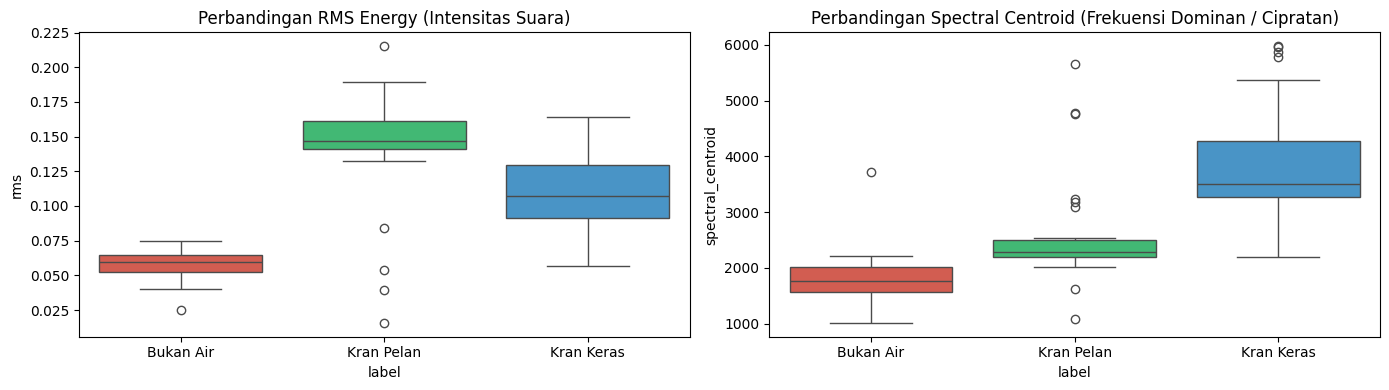

In [15]:
plt.figure(figsize=(14, 4))

palette = ['#e74c3c', '#2ecc71', '#3498db']
labels = ['Bukan Air', 'Kran Pelan', 'Kran Keras']

plt.subplot(1, 2, 1)
sns.boxplot(x='label', y='rms', data=df, palette=palette)
plt.xticks([0, 1, 2], labels)
plt.title('Perbandingan RMS Energy (Intensitas Suara)')

plt.subplot(1, 2, 2)
sns.boxplot(x='label', y='spectral_centroid', data=df, palette=palette)
plt.xticks([0, 1, 2], labels)
plt.title('Perbandingan Spectral Centroid (Frekuensi Dominan / Cipratan)')

plt.tight_layout()
plt.show()

## 4. Validasi Silang Berbasis Rekaman Sumber

In [16]:
feature_cols = [c for c in df.columns if c not in ['file_id', 'label']]
X = df[feature_cols].to_numpy()
y = df['label'].to_numpy()
groups = df['file_id'].to_numpy()
classes = np.sort(np.unique(y))

# Setiap rekaman sumber hanya masuk ke satu fold; tidak ada potongan rekaman
# yang sama pada data latih dan data uji.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
oof_proba = np.zeros((len(y), len(classes)))

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
    fold_model = ExtraTreesClassifier(
        n_estimators=500,
        max_features='sqrt',
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    fold_model.fit(X[train_idx], y[train_idx])
    fold_proba = fold_model.predict_proba(X[test_idx])
    for model_col, class_label in enumerate(fold_model.classes_):
        result_col = np.flatnonzero(classes == class_label)[0]
        oof_proba[test_idx, result_col] = fold_proba[:, model_col]
    print(f'Fold {fold}: {len(np.unique(groups[test_idx]))} rekaman sumber diuji, '
          f'{len(test_idx)} jendela audio.')

# Gabungkan probabilitas jendela menjadi satu prediksi untuk setiap rekaman.
record_rows = []
for file_id, row_indices in df.groupby('file_id', sort=True).indices.items():
    row_indices = np.asarray(row_indices)
    actual_labels = np.unique(y[row_indices])
    if len(actual_labels) != 1:
        raise ValueError(f'file_id {file_id} memiliki label yang tidak konsisten.')
    mean_proba = oof_proba[row_indices].mean(axis=0)
    record_rows.append({
        'file_id': file_id,
        'y_true': int(actual_labels[0]),
        'y_pred': int(classes[np.argmax(mean_proba)]),
        'confidence': float(np.max(mean_proba))
    })
record_metrics = pd.DataFrame(record_rows)

# Model final hanya untuk analisis fitur/pemakaian berikutnya, bukan untuk
# menghitung metrik evaluasi silang di atas.
model = ExtraTreesClassifier(
    n_estimators=500,
    max_features='sqrt',
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
model.fit(X, y)
print(f'Validasi selesai: {len(record_metrics)} rekaman sumber, '
      f'{len(y)} jendela; metrik utama dihitung per rekaman.')

Fold 1: 3 rekaman sumber diuji, 27 jendela audio.
Fold 2: 3 rekaman sumber diuji, 27 jendela audio.
Fold 3: 3 rekaman sumber diuji, 27 jendela audio.
Validasi selesai: 9 rekaman sumber, 81 jendela; metrik utama dihitung per rekaman.


## 5. Evaluasi pada Rekaman yang Tidak Dilihat Model

**Hasil aktual dataset saat ini:** akurasi level rekaman **77,78% (7/9)** dan macro F1 **77,78%**, dihitung dengan 3-fold Stratified Group Cross-Validation. Angka ini menggantikan akurasi 100% dari split acak per jendela yang bocor antar-potongan rekaman.

> Dataset baru mencakup 9 rekaman (3 per kelas), jadi skor ini masih sangat tidak stabil dan bukan jaminan performa di lokasi. Tambahkan rekaman independen dari perangkat/ruang berbeda untuk mengukur generalisasi.


METRIK UTAMA - 3-FOLD STRATIFIED GROUP CROSS-VALIDATION
Unit evaluasi: rekaman sumber (probabilitas jendela dirata-ratakan per rekaman)
Akurasi rekaman: 77.78% (7/9 rekaman benar)
Jumlah rekaman: 9 (81 jendela dari 9 sumber)


,file_id,Aktual,Prediksi,confidence,Hasil
0,0,Bukan Air,Bukan Air,0.922119,Benar
1,1,Bukan Air,Bukan Air,0.856963,Benar
2,2,Bukan Air,Bukan Air,0.810556,Benar
3,3,Kran Pelan,Kran Pelan,0.659778,Benar
4,4,Kran Pelan,Kran Pelan,0.488926,Benar
5,5,Kran Pelan,Kran Keras,0.636222,Salah
6,6,Kran Keras,Kran Keras,0.546948,Benar
7,7,Kran Keras,Kran Pelan,0.606944,Salah
8,8,Kran Keras,Kran Keras,0.775537,Benar


Classification Report per rekaman:
              precision    recall  f1-score   support

   Bukan Air     1.0000    1.0000    1.0000         3
  Kran Pelan     0.6667    0.6667    0.6667         3
  Kran Keras     0.6667    0.6667    0.6667         3

    accuracy                         0.7778         9
   macro avg     0.7778    0.7778    0.7778         9
weighted avg     0.7778    0.7778    0.7778         9



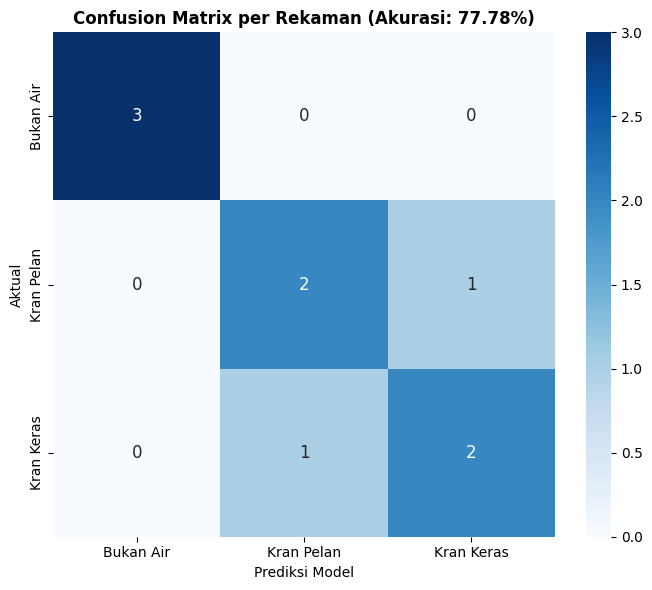

Catatan: jumlah rekaman uji masih sangat kecil; hasil ini belum mewakili akurasi di lokasi atau jaminan penghematan air.


In [17]:
class_names = ['Bukan Air', 'Kran Pelan', 'Kran Keras']
acc = accuracy_score(record_metrics['y_true'], record_metrics['y_pred'])
cm = confusion_matrix(record_metrics['y_true'], record_metrics['y_pred'], labels=classes)

print('METRIK UTAMA - 3-FOLD STRATIFIED GROUP CROSS-VALIDATION')
print('Unit evaluasi: rekaman sumber (probabilitas jendela dirata-ratakan per rekaman)')
print(f'Akurasi rekaman: {acc:.2%} '
      f'({int((record_metrics["y_true"] == record_metrics["y_pred"]).sum())}/'
      f'{len(record_metrics)} rekaman benar)')
print(f'Jumlah rekaman: {len(record_metrics)} '
      f'({len(y)} jendela dari {df["file_id"].nunique()} sumber)')

record_metrics_view = record_metrics.copy()
record_metrics_view['Aktual'] = record_metrics_view['y_true'].map(dict(enumerate(class_names)))
record_metrics_view['Prediksi'] = record_metrics_view['y_pred'].map(dict(enumerate(class_names)))
record_metrics_view['Hasil'] = np.where(
    record_metrics_view['y_true'] == record_metrics_view['y_pred'], 'Benar', 'Salah'
)
display(record_metrics_view[['file_id', 'Aktual', 'Prediksi', 'confidence', 'Hasil']])

print('Classification Report per rekaman:')
print(classification_report(
    record_metrics['y_true'], record_metrics['y_pred'],
    labels=classes, target_names=class_names, digits=4, zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={'size': 12})
plt.title(f'Confusion Matrix per Rekaman (Akurasi: {acc:.2%})',
          fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

print('Catatan: jumlah rekaman uji masih sangat kecil; hasil ini belum mewakili '
      'akurasi di lokasi atau jaminan penghematan air.')

## 6. Fitur Paling Berpengaruh (Feature Importance)

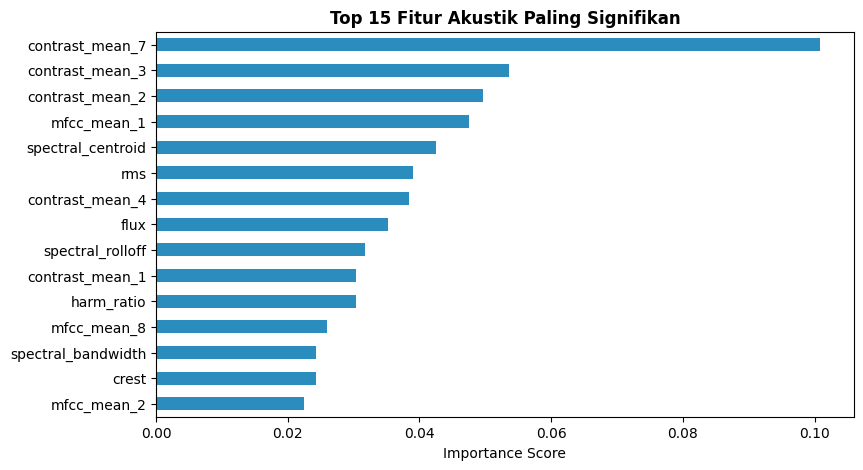

In [18]:
plt.figure(figsize=(9, 5))
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
importances.plot(kind='barh', color='#2b8cbe')
plt.title('Top 15 Fitur Akustik Paling Signifikan', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.show()